# Dataset exploration

## Connect
Read-only: blocked while `clean_data.py` runs.

In [1]:
from pathlib import Path

import duckdb

DB = Path("../data/clean/clean.duckdb")
con = duckdb.connect(str(DB), read_only=True)

# final tables only: no pipeline layers, rejects or logs
FINALS = """
SELECT table_name FROM duckdb_tables()
WHERE NOT contains(table_name, '__') AND NOT starts_with(table_name, 'pipeline_')
"""

## Row counts

In [2]:
tables = [t for (t,) in con.sql(FINALS + "ORDER BY 1").fetchall()]
con.sql(" UNION ALL ".join(f"SELECT '{t}' AS tbl, count(*) AS n_rows FROM {t}" for t in tables)).df()

,tbl,n_rows
0,bookies,35
1,closing_odds,479076
2,odds_series,640376064
3,odds_series_matches,128252


## Schema

In [3]:
for t in tables:
    print(t)
    display(con.sql(f"SELECT column_name, column_type, \"null\" FROM (DESCRIBE {t})").df())

bookies


,column_name,column_type,null
0,bookie,VARCHAR,YES
1,book_index,INTEGER,YES
2,book,INTEGER,YES
3,alias,BOOLEAN,YES


closing_odds


,column_name,column_type,null
0,match_id,BIGINT,YES
1,league,VARCHAR,YES
2,match_date,DATE,YES
3,home_team,VARCHAR,YES
4,home_score,BIGINT,YES
5,away_team,VARCHAR,YES
6,away_score,BIGINT,YES
7,avg_odds_home_win,DOUBLE,YES
8,avg_odds_draw,DOUBLE,YES
9,avg_odds_away_win,DOUBLE,YES


odds_series


,column_name,column_type,null
0,source,VARCHAR,YES
1,match_id,BIGINT,YES
2,odds,DOUBLE,YES
3,outcome,VARCHAR,YES
4,book,INTEGER,YES
5,step,INTEGER,YES


odds_series_matches


,column_name,column_type,null
0,source,VARCHAR,YES
1,match_id,BIGINT,YES
2,league,VARCHAR,YES
3,home_team,VARCHAR,YES
4,away_team,VARCHAR,YES
5,score,VARCHAR,YES
6,detailed_score,VARCHAR,YES
7,match_datetime,TIMESTAMP,YES


## Known league
Top-5 leagues, matches per source.

In [4]:
TOP5 = [
    "England: Premier League",
    "Spain: Primera Division",  # renamed in B
    "Spain: LaLiga",
    "Italy: Serie A",
    "Germany: Bundesliga",
    "France: Ligue 1",
]
con.sql(f"""
SELECT league, count(*) FILTER (source = 'a') AS n_a, count(*) FILTER (source = 'b') AS n_b
FROM odds_series_matches
WHERE league IN {tuple(TOP5)}
GROUP BY league
ORDER BY league
""").df()

,league,n_a,n_b
0,England: Premier League,228,224
1,France: Ligue 1,238,223
2,Germany: Bundesliga,180,193
3,Italy: Serie A,250,229
4,Spain: LaLiga,0,113
5,Spain: Primera Division,240,120


In [5]:
LEAGUE = 'France: Ligue 1'

## Closing odds per book
Match in `LEAGUE` with the most books quoting at step 71. Closing = last valid quote (not NULL, > 1); step 71 = nearest kickoff is an assumption.

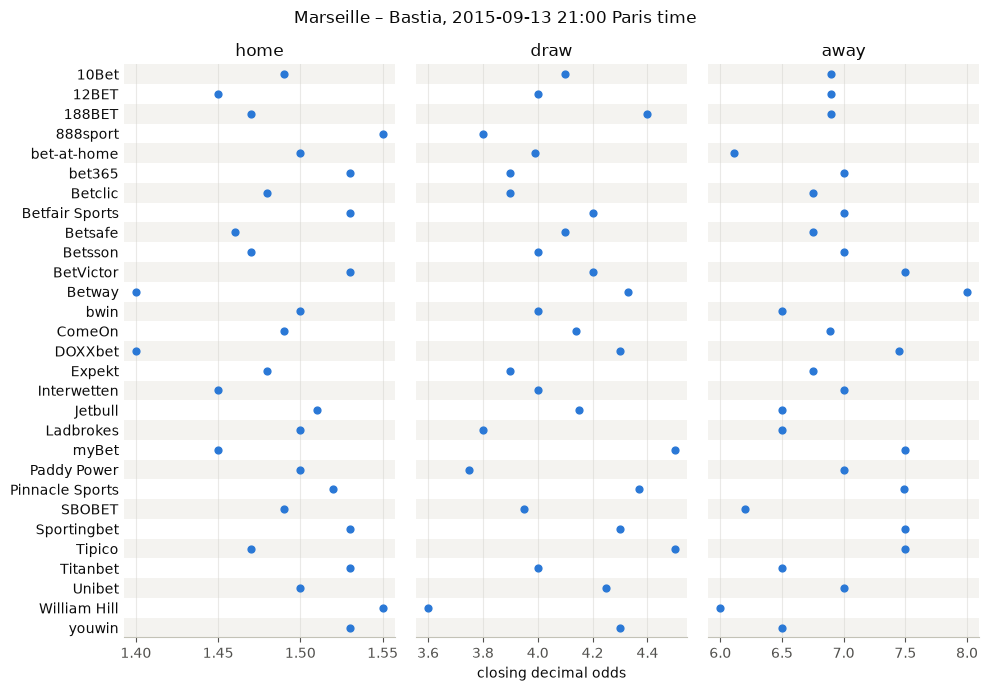

In [8]:
import matplotlib.pyplot as plt

VALID = "s.odds > 1"  # also drops NULL (missing quote)

# light figure whatever the notebook theme
LIGHT = {
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#ffffff",
    "savefig.facecolor": "#ffffff",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#0b0b0b",
    "axes.edgecolor": "#c3c2b7",
    "xtick.color": "#52514e",
    "ytick.color": "#0b0b0b",
}

match = con.sql(f"""
SELECT m.source, m.match_id, m.home_team, m.away_team, m.match_datetime
FROM odds_series_matches m JOIN odds_series s USING (source, match_id)
WHERE m.league = '{LEAGUE}' AND s.step = 71 AND {VALID}
GROUP BY ALL
ORDER BY count(DISTINCT s.book) DESC, m.match_datetime
LIMIT 1
""").df().iloc[0]

closing = con.sql(f"""
SELECT b.bookie, s.outcome, arg_max(s.odds, s.step) AS odds_close
FROM odds_series s JOIN bookies b ON b.book = s.book AND NOT b.alias
WHERE s.source = '{match.source}' AND s.match_id = {match.match_id} AND {VALID}
GROUP BY ALL
""").df()

order = sorted(closing.bookie.unique(), key=str.lower, reverse=True)  # A at the top
with plt.rc_context(LIGHT):
    fig, axes = plt.subplots(1, 3, sharey=True, figsize=(10, 7))
    for ax, outcome in zip(axes, ["home", "draw", "away"]):
        d = closing[closing.outcome == outcome].set_index("bookie").reindex(order)
        ax.scatter(d.odds_close, d.index, s=24, color="#2a78d6", zorder=3)
        for i in range(0, len(order), 2):  # zebra rows
            ax.axhspan(i - 0.5, i + 0.5, color="#f4f3f0", lw=0, zorder=0)
        ax.set_ylim(-0.5, len(order) - 0.5)
        ax.set_title(outcome)
        ax.grid(axis="x", color="#d6d5d0", lw=0.8, zorder=1)  # above the zebra
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="y", length=0)
    axes[1].set_xlabel("closing decimal odds")
    fig.suptitle(f"{match.home_team} – {match.away_team}, {match.match_datetime:%Y-%m-%d %H:%M} Paris time")
    fig.tight_layout()